# Rubin DR1-like SN Ia Simulation

This notebook simulates a DR1-like sample of Type Ia supernovae using [sncosmo](https://sncosmo.readthedocs.io/en/stable/)'s SALT3-NIR model and a Rubin OpSim (simulated survey). It scales up the [Rubin DP2 notebook](jem-rubin_dp2.ipynb): the noise model and fitting are the same, but the survey is the first year of the LSST Wide-Fast-Deep (WFD) survey and the redshifts follow the SN Ia volumetric rate out to z = 1.

The main differences from DP2 are:
* **Survey:** an OpSim (one row per visit) instead of the `rubin_DP2.ipynb` notebook's visit-detector table (one row per CCD). Each visit is treated as a 1.75 degree radius circle, so no detector footprint is needed. The default OpSim for this notebook is [LSST baseline v5.3.7](https://s3df.slac.stanford.edu/data/rubin/sim-data/sims_featureScheduler_runs5.3/baseline/baseline_v5.3.7_10yrs.db) but update this to whatever you like. Sim files are available here: [https://s3df.slac.stanford.edu/data/rubin/sim-data/](https://s3df.slac.stanford.edu/data/rubin/sim-data/)
* **Window:** the first year of the survey, WFD visits only (no deep drilling fields).
* **Redshifts:** drawn from the volumetric rate, so the simulated sample is a random subsample of the full year-one population. We keep track of the scale factor between the two.
* **SN Ia model:** SALT3-NIR ([Pierel et al. 2022](https://scixplorer.org/abs/2022ApJ...939...11P/abstract)) instead of `salt2-h17`, with x1, c, alpha, and beta updated to representative values from the DES-SN5YR reanalysis ([Popovic et al. 2026a](https://scixplorer.org/abs/2026MNRAS.548ag632P/abstract)). The model is set by `SALT_MODEL` and is used for both the simulation and the fits.
* **Fitting:** many more objects to fit, so the fits run in parallel using the helper functions in [salt_fitting.py](salt_fitting.py).

## Requirements

```
lightcurvelynx
jinja2
iminuit
```

## Configuration

All of the settings we may want to change are collected here. `N_SIM` sets the size of the subsample. The full rate-normalized population for year one is computed below and is a few million objects.

In [1]:
import numpy as np
from pathlib import Path

LCL_BASE_DIR = Path.cwd()
OPSIM_FILE = LCL_BASE_DIR / ".." / ".." / "baseline_v5.3.6_10yrs.db"
OUTPUT_DIR = LCL_BASE_DIR / ".." / ".." / "dr1_snia_with_cov"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# The sncosmo SN Ia model, used both to simulate and to fit the light curves.
SALT_MODEL = "salt3-nir"

N_SIM = 50_000  # The number of objects to simulate (a subsample of the full population).
SEED = 42

SURVEY_DAYS = 365.25  # Length of the survey window (the first year).
Z_MIN, Z_MAX = 0.01, 1.0

# Cosmology used for both the rates and the distance moduli.
H0, OMEGA_M = 73.0, 0.3
# The simulation uses a flat LambdaCDM cosmology, so w0 is always -1. It is only named here
# so it can be recorded in the sim config file; changing it does not change the simulation.
W0 = -1.0

# Population / Tripp parameters (also used below to propagate fit covariance).
ALPHA, BETA, M0 = 0.17, 3.12, -19.3
# The Gaussian populations that x1 and c are sampled from (mean, standard deviation).
X1_MEAN, X1_SIGMA = 0.0, 1.0
C_MEAN, C_SIGMA = 0.0, 0.1

# Scatter in absolute magnitude for x0 calculation. 0.1 is a reasonable value;
# 0.3-0.5 would be "inflated" scatter.
M_abs_scatter = 0.5

# The rest-frame window of the light curves (same as DP2).
REST_WINDOW = (-20.0, 50.0)

# t0 is sampled from slightly outside the survey window, so that objects which peak just before
# the survey starts (or just after it ends) still contribute their partial light curves.
# At z = 1, the rest-frame window above covers observer-frame [-40, +100] days.
T0_PAD_BEFORE = REST_WINDOW[1] * (1.0 + Z_MAX)  # 100 days
T0_PAD_AFTER = -REST_WINDOW[0] * (1.0 + Z_MAX)  # 40 days

## Load the first year of WFD visits

We load the OpSim with an SQL query that selects only the first year of WFD visits. In the v5.x baselines, each visit has a `target_name` that records which part of the survey footprint it belongs to. `lowdust` is the extragalactic WFD region, and the others are the Galactic plane (`dusty_plane`, `bulgy`), the North Ecliptic Spur (`nes`), the South Celestial Pole (`scp`), and the Magellanic Clouds. We also drop deep drilling field visits (whose `scheduler_note` starts with `DD:`) and target-of-opportunity visits (`ToO`), even when they fall inside the WFD region.

Selecting in SQL also avoids `filter_rows()`, which modifies the `ObsTable` **in place** (and returns the same object) rather than returning a copy.

Note that much of the first year is spent building templates (`scheduler_note` starting with `templates`). These are ordinary visits and we keep them.

In [2]:
import sqlite3

from lightcurvelynx.obstable.opsim import OpSim

with sqlite3.connect(OPSIM_FILE) as con:
    t_start = con.execute("SELECT MIN(observationStartMJD) FROM observations").fetchone()[0]
t_end = t_start + SURVEY_DAYS

wfd_query = f"""
SELECT * FROM observations
WHERE observationStartMJD < {t_end}
  AND target_name LIKE '%lowdust%'
  AND scheduler_note NOT LIKE 'DD%'
  AND scheduler_note NOT LIKE 'ToO%'
"""
obs_table = OpSim.from_db(OPSIM_FILE, sql_query=wfd_query)

print(f"Loaded {len(obs_table)} WFD visits between MJD {t_start:.1f} and {t_end:.1f}")
print("Visits per filter:", dict(zip(*np.unique(obs_table["filter"], return_counts=True))))

/home/connor/Documents/Life_2026/Fall/spartan/lclvenv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/connor/Documents/Life_2026/Fall/spartan/lclvenv/lib/python3.12/site-packages/lightcurvelynx/obstable/obs_table.py:197: UserWarning: Column 'scheduler_note' has more than 100 unique string values. We are skipping the conversion to categorical. This may impact performance and memory usage with parallel computation. Consider dropping this column if it is not needed for your analysis.
  warnings.warn(


Loaded 87625 WFD visits between MJD 61208.2 and 61573.5
Visits per filter: {'g': np.int64(11522), 'i': np.int64(14540), 'r': np.int64(18808), 'u': np.int64(11189), 'y': np.int64(15419), 'z': np.int64(16147)}


We create the rest of the survey information by using the standard LSST passbands and noise model (Poisson), as in the `rubin_DP2.ipynb` notebook. The OpSim provides everything the noise model needs: the zero points are derived from the airmass, exposure time, and filter; the sky background from the sky brightness; and the PSF size from the seeing. The camera properties (read noise, dark current, pixel scale) are LSSTCam defaults stored in the `OpSim` class.

In [3]:
from lightcurvelynx.astro_utils.passbands import PassbandGroup
from lightcurvelynx.survey_info import SurveyInfo

passband_group = PassbandGroup.from_preset(preset="LSST")
survey_info = SurveyInfo(obstable=obs_table, passbands=passband_group, survey_name="LSST")

## The rate-normalized redshift distribution

Instead of sampling the redshift uniformly, we sample it from the number of SNe Ia expected per unit redshift:

$$\frac{dN}{dz} \propto r_v(z) \, \frac{dV_c}{dz} \, \frac{1}{1+z}$$

where $r_v(z) = 2.27 \times 10^{-5} (1+z)^{1.7}$ SNe yr $^{-1}$ Mpc $^{-3}$ $h_{70}^3$ is the volumetric rate from [Frohmaier et al. (2019)](https://ui.adsabs.harvard.edu/abs/2019MNRAS.486.2308F), $dV_c/dz$ is the comoving volume per unit redshift, and the $1/(1+z)$ accounts for cosmological time dilation. These are the defaults in LightCurveLynx's `snia_volumetric_rates()` and `num_snia_per_redshift_bin()`.

To get the total number of SNe in the survey, we multiply by the area of the WFD footprint and the length of the window over which t0 is sampled (the survey year plus the padding on either side). The footprint area comes from the MOC* of the visits, so it includes the 1.75 degree circle around each pointing at the edges of the footprint.

*A multi-order coverage map (MOC) is a data structure for efficiently representing a spatial region on a sphere. 

In [4]:
from lightcurvelynx.astro_utils.snia_utils import num_snia_per_redshift_bin

moc = obs_table.build_moc(max_depth=10)
area_deg2 = moc.sky_fraction * 41253.0
solid_angle = area_deg2 * (np.pi / 180.0) ** 2

t0_low, t0_high = t_start - T0_PAD_BEFORE, t_end + T0_PAD_AFTER
t0_years = (t0_high - t0_low) / 365.25

n_per_bin, z_bins = num_snia_per_redshift_bin(
    zmin=Z_MIN, zmax=Z_MAX, znbins=99, solid_angle=solid_angle, H0=H0, Omega_m=OMEGA_M
)
n_total = n_per_bin.sum() * t0_years
scale_factor = n_total / N_SIM

print(f"WFD footprint area: {area_deg2:.0f} deg^2")
print(f"t0 window: {t0_high - t0_low:.0f} days ({t0_years:.2f} years)")
print(f"Expected number of SNe Ia with {Z_MIN} < z < {Z_MAX}: {n_total:,.0f}")
print(f"Simulating {N_SIM:,} objects, so each one represents {scale_factor:.1f} real SNe.")

WFD footprint area: 19744 deg^2
t0 window: 505 days (1.38 years)
Expected number of SNe Ia with 0.01 < z < 1.0: 3,291,207
Simulating 50,000 objects, so each one represents 65.8 real SNe.


We use `SamplePDF` to draw redshifts from this distribution. It only needs a function proportional to the PDF, so we do not have to normalize it.

In [5]:
from astropy.cosmology import FlatLambdaCDM

from lightcurvelynx.astro_utils.snia_utils import snia_volumetric_rates
from lightcurvelynx.math_nodes.scipy_random import SamplePDF

cosmo = FlatLambdaCDM(H0=H0, Om0=OMEGA_M)


def snia_dndz(z):
    """The (unnormalized) number of SNe Ia per unit redshift per year of observer time."""
    return snia_volumetric_rates(z) * cosmo.differential_comoving_volume(z).value / (1.0 + z)


redshift_sampler = SamplePDF(snia_dndz, domain=(Z_MIN, Z_MAX))

## Create the model

Positions are sampled uniformly over the survey footprint, as was done in DP2. The $x_1$ and $c$ distributions and the Tripp $\alpha$ and $\beta$ are updated from the DP2 placeholder values to representative values from the DES-SN5YR SN Ia cosmology reanalysis ([B. Popovic et al. 2026](https://scixplorer.org/abs/2026MNRAS.548ag632P/abstract)). The absolute magnitude distribution is unchanged from the previous notebook, except that now the scatter is a tunable parameter `M_abs_scatter` whose value is set in the configuration section. 

The time window for t0 covers the survey year plus the padding described above.

In [6]:
from lightcurvelynx.astro_utils.snia_utils import DistModFromRedshift, X0FromDistMod
from lightcurvelynx.math_nodes.np_random import NumpyRandomFunc
from lightcurvelynx.math_nodes.ra_dec_sampler import ApproximateMOCSampler

# Sample position (RA, dec) uniformly from the footprint of the survey. This sampler
# will take multiple seconds to build as it creates a MOC of the survey footprint.
coverage_sampler = ApproximateMOCSampler.from_obstable(obs_table, depth=10)

# Compute the distance modulus from the redshift, using the same cosmology as the rates.
distmod_func = DistModFromRedshift(redshift_sampler, H0=H0, Omega_m=OMEGA_M, node_label="distmod")

# Sample x1, c using more representative scatters for x1 and c.
# The node labels give the sampled values stable names (for example "x0.m_abs") in the
# saved parameters, which the truth columns of the light curve file are built from below.
x1_func = NumpyRandomFunc("normal", loc=X1_MEAN, scale=X1_SIGMA, node_label="x1")
c_func = NumpyRandomFunc("normal", loc=C_MEAN, scale=C_SIGMA, node_label="c")
# Also sample standardized absolute magnitude:
M_abs_func = NumpyRandomFunc("normal", loc=M0, scale=M_abs_scatter, node_label="M_abs")

# Compute x0 from the other parameters using the standard Tripp formula.
x0_func = X0FromDistMod(
    distmod=distmod_func,
    x1=x1_func,
    c=c_func,
    alpha=ALPHA,
    beta=BETA,
    m_abs=M_abs_func,
    node_label="x0",
)

# t0 is sampled uniformly over the (padded) survey window.
t0_func = NumpyRandomFunc("uniform", low=t0_low, high=t0_high)

We then define the model using the `SncosmoWrapperModel` class, with the same `LinearDecay` time extrapolation as DP2.

At the higher redshifts in this sample we also need a **wavelength** extrapolation. SALT3-NIR (like SALT2) is only defined above 2000 Å in the rest frame, and at z ≳ 0.5 the blue edge of the u band falls below that. We use `ZeroPadding`, which sets the flux to zero outside the model's wavelength range. The fitting code below only uses bands whose rest-frame effective wavelength is above 2800 Å (see below), so these partially-covered bands do not affect the fits.

In [7]:
from lightcurvelynx.models.sncosmo_models import SncosmoWrapperModel
from lightcurvelynx.utils.extrapolate import LinearDecay, ZeroPadding

source = SncosmoWrapperModel(
    SALT_MODEL,
    t0=t0_func,
    x0=x0_func,
    x1=x1_func,
    c=c_func,
    ra=coverage_sampler.ra,
    dec=coverage_sampler.dec,
    redshift=redshift_sampler,
    node_label="source",
    time_extrapolation=LinearDecay(
        50.0
    ),  # Linear decay to zero over 50 days past the model's phase range.
    wave_extrapolation=ZeroPadding(),  # Zero flux outside the model's wavelength range.
)

## Generate the simulations

We restrict the simulations to the same rest-frame window as `rubin_dp2.ipynb`. For 50,000 objects this takes under a minute.

We save the results to a parquet file so the fits can be rerun later without resimulating. This file is the **truth catalog**: one row per simulated object (whether or not it was observed), with the object's index in `id`. Besides the columns LightCurveLynx always writes (the true `ra`, `dec`, `t0`, and `z`, the number of observations, and the light curve), it has a `true_*` column for each remaining per-object truth value: the SALT parameters `true_x0`, `true_x1`, `true_c`; the peak apparent magnitude `true_mB` (-2.5 log10(x0) + 10.635); the standardized absolute magnitude `true_M_abs` (`M0` plus that object's intrinsic scatter); and the distance modulus `true_mu`, so that `true_mu = true_mB + alpha * true_x1 - beta * true_c - true_M_abs`. The `params` column still holds the complete dictionary of sampled parameters for each object.

The settings that are the same for every object are saved next to it in `sim_config_*.npz`, a dictionary of values: the cosmology (`H0`, `Omega_m`, `w0`), the redshift range (`z_min`, `z_max`), `N_SIM`, the Tripp parameters (`alpha`, `beta`, `M0`, `M_abs_scatter`), the x1 and c populations (`x1_mean`, `x1_sigma`, `c_mean`, `c_sigma`), `seed`, and `salt_model`.

In [8]:
from lightcurvelynx.simulate import simulate_lightcurves

# The truth values to save as their own columns of the light curve file, read from the
# parameters LightCurveLynx actually sampled for each object ("node_label.parameter").
# ra, dec, t0, and z (all true values) are always saved as columns by LightCurveLynx.
TRUTH_COLS = {
    # Per-object SALT parameters.
    "source.x0": "true_x0",
    "source.x1": "true_x1",
    "source.c": "true_c",
    # Per-object standardized absolute magnitude (M0 plus this object's intrinsic scatter)
    # and distance modulus.
    "x0.m_abs": "true_M_abs",
    "x0.distmod": "true_mu",
}

lightcurves = simulate_lightcurves(
    source,
    N_SIM,
    survey_info,
    rest_time_window_offset=REST_WINDOW,
    param_cols=list(TRUTH_COLS),
    rng=np.random.default_rng(SEED),
)

# LightCurveLynx names each saved parameter column "node_parameter"; rename them to true_*.
lightcurves = lightcurves.rename(
    columns={name.replace(".", "_"): new_name for name, new_name in TRUTH_COLS.items()}
).astype({new_name: float for new_name in TRUTH_COLS.values()})

# The true peak apparent B-band magnitude (same convention as fit_mB below), so that
# true_mu = true_mB + ALPHA * true_x1 - BETA * true_c - true_M_abs.
lightcurves["true_mB"] = -2.5 * np.log10(lightcurves["true_x0"]) + 10.635

lightcurves.to_parquet(OUTPUT_DIR / f"lightcurves_{SALT_MODEL}_n{N_SIM}_seed{SEED}.parquet")

# The settings of the simulation, which are the same for every object, go in their own
# file as a dictionary of values. To load it as plain Python values:
#     sim_config = {key: value.item() for key, value in np.load(path).items()}
sim_config = {
    "H0": H0,
    "Omega_m": OMEGA_M,
    "w0": W0,
    "z_min": Z_MIN,
    "z_max": Z_MAX,
    "N_SIM": N_SIM,
    "alpha": ALPHA,
    "beta": BETA,
    "M0": M0,
    "M_abs_scatter": M_abs_scatter,
    "x1_mean": X1_MEAN,
    "x1_sigma": X1_SIGMA,
    "c_mean": C_MEAN,
    "c_sigma": C_SIGMA,
    "seed": SEED,
    "salt_model": SALT_MODEL,
}
np.savez(OUTPUT_DIR / f"sim_config_{SALT_MODEL}_n{N_SIM}_seed{SEED}.npz", **sim_config)

# Keep the parameters column separately for the plots and fits below.
params_col = lightcurves["params"].copy()
lightcurves = lightcurves.drop(columns=["params"])
lightcurves.head()

Simulating: 100%|██████████| 50000/50000 [01:43<00:00, 481.10obj/s]


id          ra        dec            t0         z  nobs   true_x0  \
0   0   20.869062  -9.836476  61208.619988  0.847912    17  0.000005   
1   1  215.464685 -31.979188  61278.669039  0.686626     1  0.000009   
2   2  156.458902 -37.918537  61388.048200  0.745819    24  0.000003   
3   3  249.357969   1.937655  61401.265605  0.493258     0  0.000005   
4   4  239.497443   2.264524  61489.904760  0.990744    31  0.000002   

    true_x1    true_c  true_M_abs  ...  true_sigma_int  true_x1_mean  \
0  0.207520 -0.031684  -19.512268  ...             0.5           0.0   
1  0.519526 -0.256868  -18.891625  ...             0.5           0.0   
2 -0.134222 -0.063350  -18.455283  ...             0.5           0.0   
3 -0.237634  0.073528  -18.501668  ...             0.5           0.0   
4  0.265956  0.002847  -18.781038  ...             0.5           0.0   

   true_x1_sigma  true_c_mean  true_c_sigma  \
0            1.0          0.0           0.1   
1            1.0          0.0           0.1   
2            1.0          0.0           0.1   
3            1.0          0.0           0.1   
4            1.0          0.0           0.1   

                                          lightcurve  spectra    true_mB  \
0  [{mjd: 61222.411567, filter: 'y', flux: 1937.6...     None  23.920507   
1  [{mjd: 61260.966481, filter: 'r', flux: 1717.4...     None  23.223182   
2  [{mjd: 61388.349707, filter: 'z', flux: 861.16...     None  24.594299   
3                                               None     None  23.902845   
4  [{mjd: 61461.337889, filter: 'z', flux: -132.4...     None  25.166784   

   true_H0 true_Omega_m  
0     73.0          0.3  
1     73.0          0.3  
2     73.0          0.3  
3     73.0          0.3  
4     73.0          0.3  

[5 rows x 24 columns]

As a check, the simulated redshifts should follow the rate-normalized distribution. The histogram also shows how many of the objects were observed at all. Objects can fall in gaps between pointings (we sample from an approximate MOC), or have t0 so far from any visit that nothing lands in the rest-frame window.

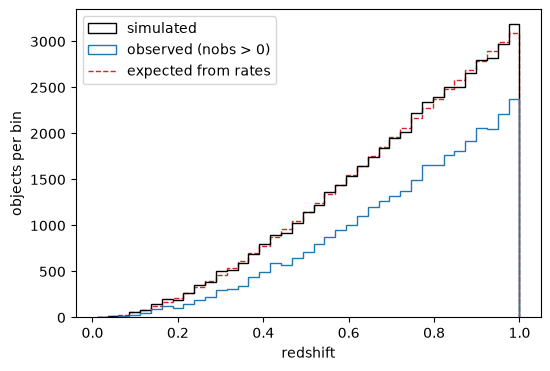

34,281 of 50,000 objects (68.6%) have at least one observation.


In [9]:
import matplotlib.pyplot as plt

true_z = lightcurves["z"].to_numpy()
observed = lightcurves["nobs"].to_numpy() > 0

bins = np.linspace(Z_MIN, Z_MAX, 40)
expected = snia_dndz(0.5 * (bins[1:] + bins[:-1])) * np.diff(bins)
expected *= N_SIM / expected.sum()

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(true_z, bins=bins, histtype="step", color="black", label="simulated")
ax.hist(true_z[observed], bins=bins, histtype="step", color="tab:blue", label="observed (nobs > 0)")
ax.stairs(expected, bins, color="tab:red", ls="--", label="expected from rates")
ax.set_xlabel("redshift")
ax.set_ylabel("objects per bin")
ax.legend()
plt.show()

print(
    f"{observed.sum():,} of {N_SIM:,} objects ({observed.mean():.1%}) have at least one observation."
)

We plot the first 3 results that contain enough sampled points to be interesting.

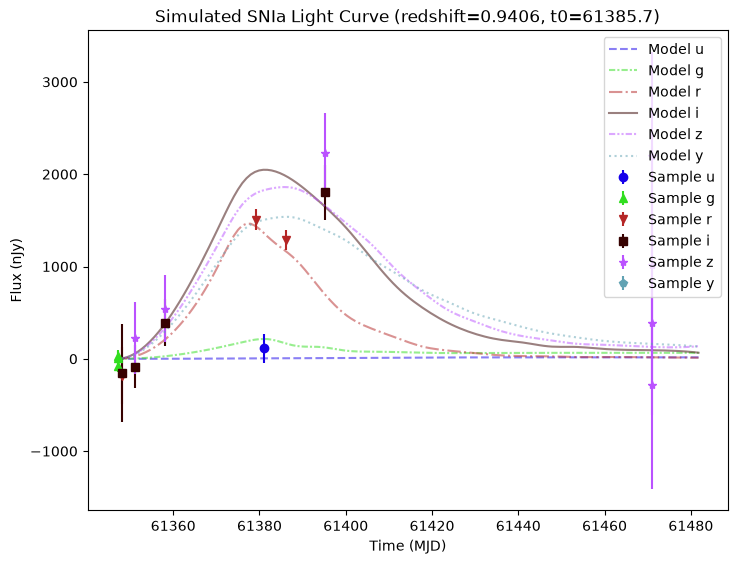

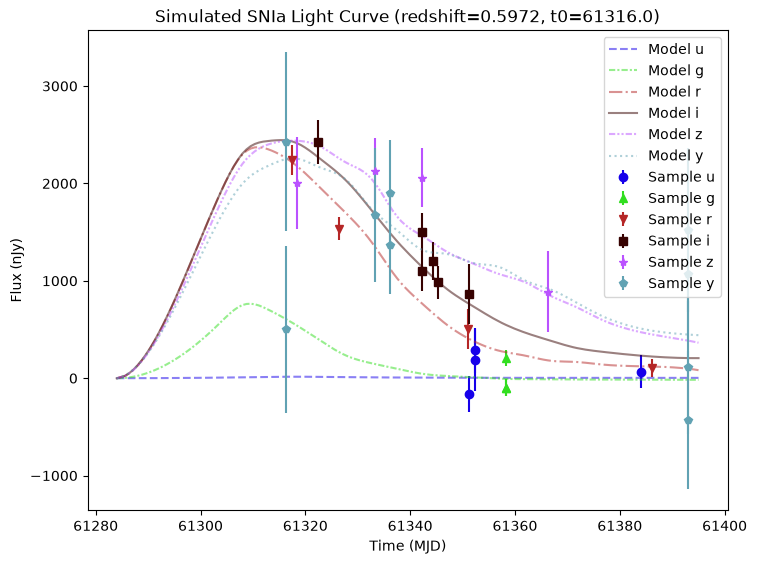

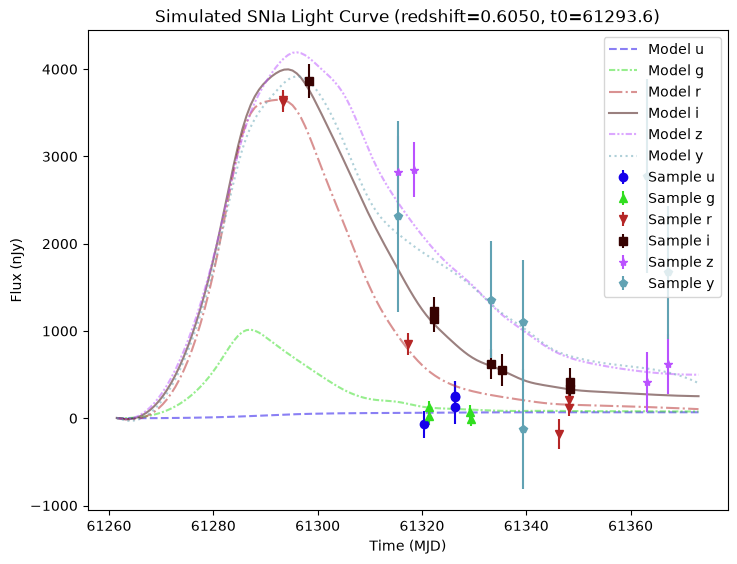

In [10]:
from lightcurvelynx.graph_state import GraphState
from lightcurvelynx.simulate import compute_single_noise_free_lightcurve
from lightcurvelynx.utils.plotting import plot_lightcurves

curr_idx = 0
count = 0
while count < 3:
    result_row = lightcurves.iloc[curr_idx]
    params_dict = params_col.iloc[curr_idx]
    curr_idx += 1

    # If we didn't observe the object at all, skip it.
    current_lc = result_row["lightcurve"]
    if current_lc is None or len(current_lc) == 0:
        continue

    lc_filters = np.asarray(current_lc["filter"], dtype=str)
    lc_mjd = np.asarray(current_lc["mjd"], dtype=float)
    lc_flux = np.asarray(current_lc["flux"], dtype=float)
    lc_fluxerr = np.asarray(current_lc["fluxerr"], dtype=float)

    # If the light curve has only a few observations, covers a very short time span, or
    # is never detected, skip it.
    if (
        len(lc_mjd) < 10
        or (np.max(lc_mjd) - np.min(lc_mjd)) < 50
        or np.max(lc_flux / lc_fluxerr) < 10
    ):
        continue

    noise_free_lcs = compute_single_noise_free_lightcurve(
        source,
        GraphState.from_dict(params_dict),
        passband_group,
        rest_frame_phase_min=REST_WINDOW[0],
        rest_frame_phase_max=REST_WINDOW[1],
        rest_frame_phase_step=0.5,
    )

    redshift = params_dict["source.redshift"]
    t0 = params_dict["source.t0"]

    plot_lightcurves(
        fluxes=lc_flux,
        times=lc_mjd,
        fluxerrs=lc_fluxerr,
        filters=lc_filters,
        underlying_model=noise_free_lcs,
        title=f"Simulated SNIa Light Curve (redshift={redshift:.4f}, t0={t0:.1f})",
    )
    count += 1

## Fit the simulated light curves with SALT3-NIR

The fitting follows DP2 exactly, using the same model as the simulation (`SALT_MODEL`): LightCurveLynx's LSST passbands registered with sncosmo, an AB zero point of 31.4 (nJy), the redshift held fixed at its true value, `t0`, `x0`, `x1`, and `c` fit with the same bounds and phase range, and bands outside the model's wavelength range dropped. Objects with fewer than 5 usable points, or no point with S/N > 5, are not fit.

One change from DP2: following Mitra et al. (2026), we only fit bands whose rest-frame effective wavelength, λ_eff / (1 + z), is between 2800 and 17,000 Å, the range where SALT3 is well trained. For LSST this drops u above z ≈ 0.33 and g above z ≈ 0.72.

The code has moved into [salt_fitting.py](salt_fitting.py) so that the fits can run in parallel. Each worker process registers the passbands with sncosmo when it starts. Unlike DP2, we fit every detected object instead of the first 200.
`sncosmo.fit_lc()` also returns a covariance matrix for the varied parameters. The `salt_fitting` helper stores its 10 independent elements as numeric columns `cov_<parameter>_<parameter>` (parameter order: t0, x0, x1, c). The fitter propagates the x0/x1/c block to a standardized distance modulus, conditional on known redshift and fixed Tripp coefficients. This is the covariance of *fitted parameters*, not `modelcov=True` (which includes SALT3 template/model uncertainty in the fitting likelihood).

In [11]:
import importlib
import os
from concurrent.futures import ProcessPoolExecutor

import pandas as pd

import salt_fitting_with_covmat as salt_fitting

# Reload in case salt_fitting.py was edited since the kernel started (a plain import would keep the old version).
importlib.reload(salt_fitting)

band_names = salt_fitting.register_passbands(passband_group)

fit_tasks = [
    (idx, lightcurves.iloc[idx]["lightcurve"], params_col.iloc[idx], SALT_MODEL, ALPHA, BETA)
    for idx in np.flatnonzero(observed)
]
with ProcessPoolExecutor(
    max_workers=os.cpu_count(), initializer=salt_fitting.register_passbands
) as executor:
    fit_rows = [
        row
        for row in executor.map(salt_fitting.fit_one, fit_tasks, chunksize=100)
        if row is not None
    ]

## The DR1-like sample

Scaling by the subsampling factor gives the predicted number of SNe Ia in year one. This depends strongly on the quality cuts. We use the light curve cuts from Mitra et al. (2026):
1. at least three bands with maximum S/N > 4 (among the points used in the fit);
2. |x1| < 3;
3. |c| < 0.3;
4. σ_x1 < 1;
5. σ_t0 < 2 days;
8. 0.01 < z < 1.4 (applied to the true redshift, so it has no effect here);
9. only fit bands with 2800 < λ_eff / (1 + z) < 17,000 Å (applied during the fit, above).

Their cuts 6 and 7 (photometric classification and spectroscopic redshift) do not apply to this simulation. We also require the fit to converge. For comparison, we also show the looser DP2 cuts (at least 5 points near peak, one S/N > 3 detection on either side of peak, and reduced χ² < 3).
The fit catalog also contains `fit_mB`, `fit_mu`, `var_mu_fit`, `err_mu_fit`, and `err_mu_total` (the last adds the configured population intrinsic scatter in quadrature). Note that `err_mu_fit` is a local Gaussian approximation, not the full sampled posterior. The selected-only fits (appropriate for a blind analysis) are written to a separate parquet file, which holds only what the observer would know: it leaves out the `true_*` parameters and the columns that use the true Tripp parameters (`fit_mu`, `var_mu_fit`, `err_mu_fit`, `err_mu_total`). Its `redshift` is the true redshift, standing in for a spectroscopic one, and its `idx` index matches `id` in the light curve (truth) file.

In [12]:
fit_results = salt_fitting.apply_quality_cuts(pd.DataFrame(fit_rows).set_index("idx"))

# Convert the fitted SALT3 amplitude to apparent B-band magnitude, then
# propagate the 3x3 (x0, x1, c) block of the fit covariance to Tripp mu.
# redshift, ALPHA, BETA, and M0 are held fixed in this approximation.
fit_results["fit_mB"] = (
    -2.5 * np.log10(fit_results["fit_x0"].where(fit_results["fit_x0"] > 0)) + 10.635
)
fit_results["fit_mu"] = (
    fit_results["fit_mB"] + ALPHA * fit_results["fit_x1"] - BETA * fit_results["fit_c"] - M0
)

# var_mu_fit and err_mu_fit were computed for each SN in salt_fitting.fit_one().
# Add the independently sampled gray intrinsic scatter for cosmology inference.
fit_results["err_mu_total"] = np.sqrt(fit_results["var_mu_fit"])  #  + M_abs_scatter**2

fit_results.to_parquet(OUTPUT_DIR / f"fits_{SALT_MODEL}_n{N_SIM}_seed{SEED}.parquet")
good_fits = fit_results[fit_results["passes_cuts"]]
# A selected-only catalog suitable for sharing in a BLIND run, holding only what the
# observer would know. Omit the injected true SALT parameters (true_*) and the columns
# computed with the true ALPHA, BETA, M0, and M_abs_scatter, which the observer has to
# infer. The private all-fits file above retains them all. The redshift column is kept:
# it is the true redshift, standing in for a spectroscopic redshift.
TRUTH_DERIVED_COLS = []  # "fit_mu", "var_mu_fit", "err_mu_fit", "err_mu_total"
selected_public = good_fits.drop(
    columns=[c for c in good_fits if c.startswith("true_")] + TRUTH_DERIVED_COLS
)
selected_public.to_parquet(OUTPUT_DIR / f"selected_fits_{SALT_MODEL}_n{N_SIM}_seed{SEED}.parquet")

print(
    f"Fit {len(fit_results):,} of the {observed.sum():,} observed objects (the rest were not detected)."
)
print(f"{len(good_fits):,} pass the Mitra et al. (2026) quality cuts.")
print(f"{fit_results['passes_dp2_cuts'].sum():,} pass the looser DP2 cuts (for comparison).")
print(
    f"Fit covariances available: {fit_results['covariance_available'].sum():,} / {len(fit_results):,}"
)
fit_results.head()

Fit 12,434 of the 34,281 observed objects (the rest were not detected).
3,287 pass the Mitra et al. (2026) quality cuts.
6,633 pass the looser DP2 cuts (for comparison).
Fit covariances available: 12,420 / 12,434


,redshift,success,ndof,chisq,n_near_peak,n_pre_peak,n_post_peak,n_bands_snr4,true_t0,fit_t0,...,cov_x1_c,cov_c_c,var_mu_fit,err_mu_fit,reduced_chisq,passes_cuts,passes_dp2_cuts,fit_mB,fit_mu,err_mu_total
idx,,,,,,,,,,,,,,,,,,,,,
6,0.940631,True,2,0.813655,4,1,2,3,61385.715736,61383.270213,...,-0.038721,0.002803,0.709336,0.842221,0.406828,False,False,23.647135,43.220411,0.842221
10,0.597227,True,18,23.995034,21,2,7,3,61315.954966,61319.050107,...,-0.028442,0.002923,0.117014,0.342074,1.333057,False,True,23.575363,43.024219,0.342074
11,0.799796,True,14,6.708035,16,1,0,2,61250.950271,61253.568235,...,0.000005,0.016128,0.333910,0.577849,0.479145,False,False,24.802846,43.654289,0.577849
15,0.879949,True,4,3.700305,7,0,2,3,61564.563638,61556.496844,...,0.039618,0.005250,1.959100,1.399678,0.925076,False,False,23.722912,42.716626,1.399678
19,0.688356,True,2,3.873487,4,0,0,2,61555.472234,61547.278408,...,0.053191,0.021213,0.333974,0.577905,1.936744,False,False,24.144984,42.852839,0.577905


           simulated:  50,000 simulated ->   3,291,207 expected in year one
 observed (nobs > 0):  34,281 simulated ->   2,256,517 expected in year one
    detected and fit:  12,434 simulated ->     818,457 expected in year one
     passes DP2 cuts:   6,633 simulated ->     436,612 expected in year one
   passes Mitra cuts:   3,287 simulated ->     216,364 expected in year one


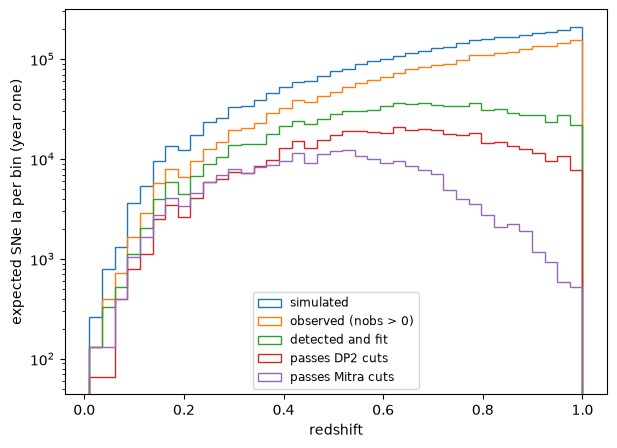

In [13]:
stages = {
    "simulated": np.ones(N_SIM, dtype=bool),
    "observed (nobs > 0)": observed,
    "detected and fit": np.isin(np.arange(N_SIM), fit_results.index),
    "passes DP2 cuts": np.isin(np.arange(N_SIM), fit_results.index[fit_results["passes_dp2_cuts"]]),
    "passes Mitra cuts": np.isin(np.arange(N_SIM), good_fits.index),
}
for name, mask in stages.items():
    print(
        f"{name:>20s}: {mask.sum():>7,d} simulated -> {mask.sum() * scale_factor:>11,.0f} expected in year one"
    )

fig, ax = plt.subplots(figsize=(7, 5))
for name, mask in stages.items():
    ax.hist(
        true_z[mask],
        bins=bins,
        histtype="step",
        label=name,
        weights=np.full(mask.sum(), scale_factor),
    )
ax.set_yscale("log")
ax.set_xlabel("redshift")
ax.set_ylabel("expected SNe Ia per bin (year one)")
ax.legend(fontsize="small")
plt.show()

We plot the fitted SALT model (solid) and the true model (dashed) on top of the noisy data for the first few objects that pass the quality cuts.

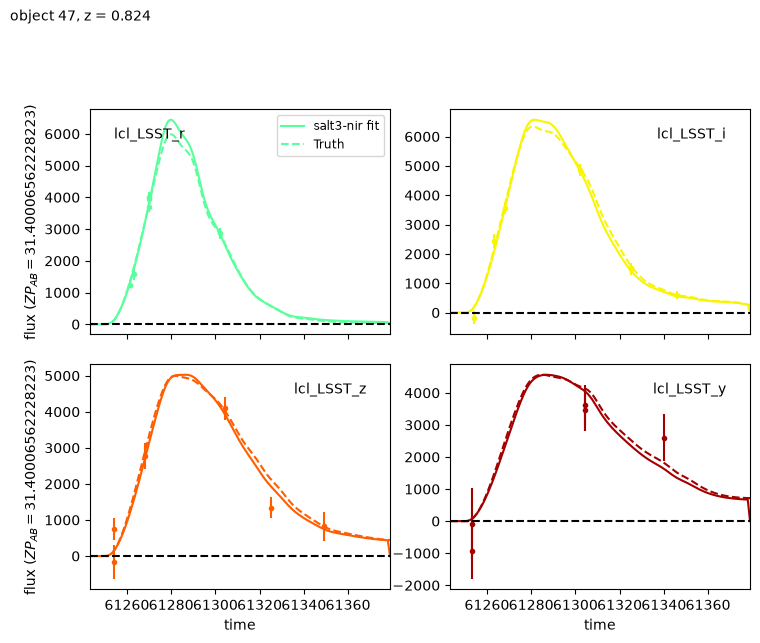

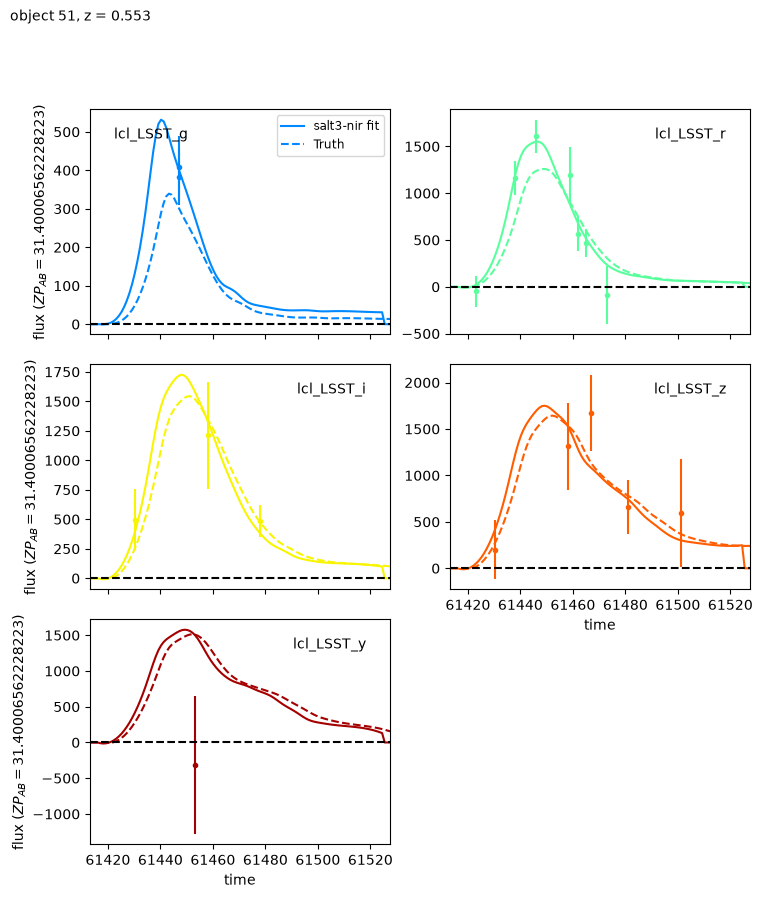

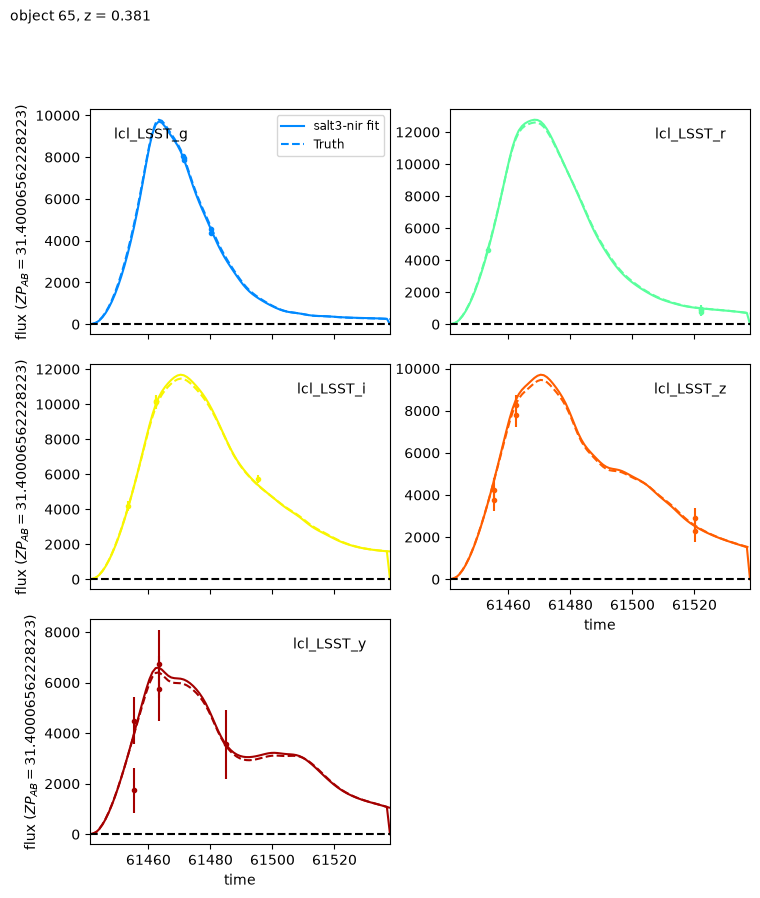

In [14]:
import sncosmo

for idx in good_fits.index[:3]:
    params_dict = params_col.iloc[idx]
    fit_model = sncosmo.Model(source=SALT_MODEL)
    data = salt_fitting.prepare_data(
        lightcurves.iloc[idx]["lightcurve"], params_dict["source.redshift"], fit_model
    )
    fit_model.set(**{name: good_fits.loc[idx, f"fit_{name}"] for name in salt_fitting.FIT_PARAMS})

    true_model = sncosmo.Model(source=SALT_MODEL)
    true_model.set(
        z=params_dict["source.redshift"],
        **{name: params_dict[f"source.{name}"] for name in salt_fitting.FIT_PARAMS},
    )
    sncosmo.plot_lc(
        data,
        model=[fit_model, true_model],
        model_label=[f"{SALT_MODEL} fit", "Truth"],
        zp=salt_fitting.ZP_NJY,
        figtext=f"object {idx}, z = {params_dict['source.redshift']:.3f}",
    )

Finally, we compare the fitted parameters to the true values for the objects passing the cuts. x0 is shown as the equivalent magnitude offset, -2.5 log10(x0_fit / x0_true).

The top row shows the residuals as a function of redshift, with the median and 16-84th percentile range in redshift bins. 

The bottom row shows the pulls: (fit - truth) / error. If the fit uncertainties are correct, these follow a unit Gaussian (black curve) with a width of 1.

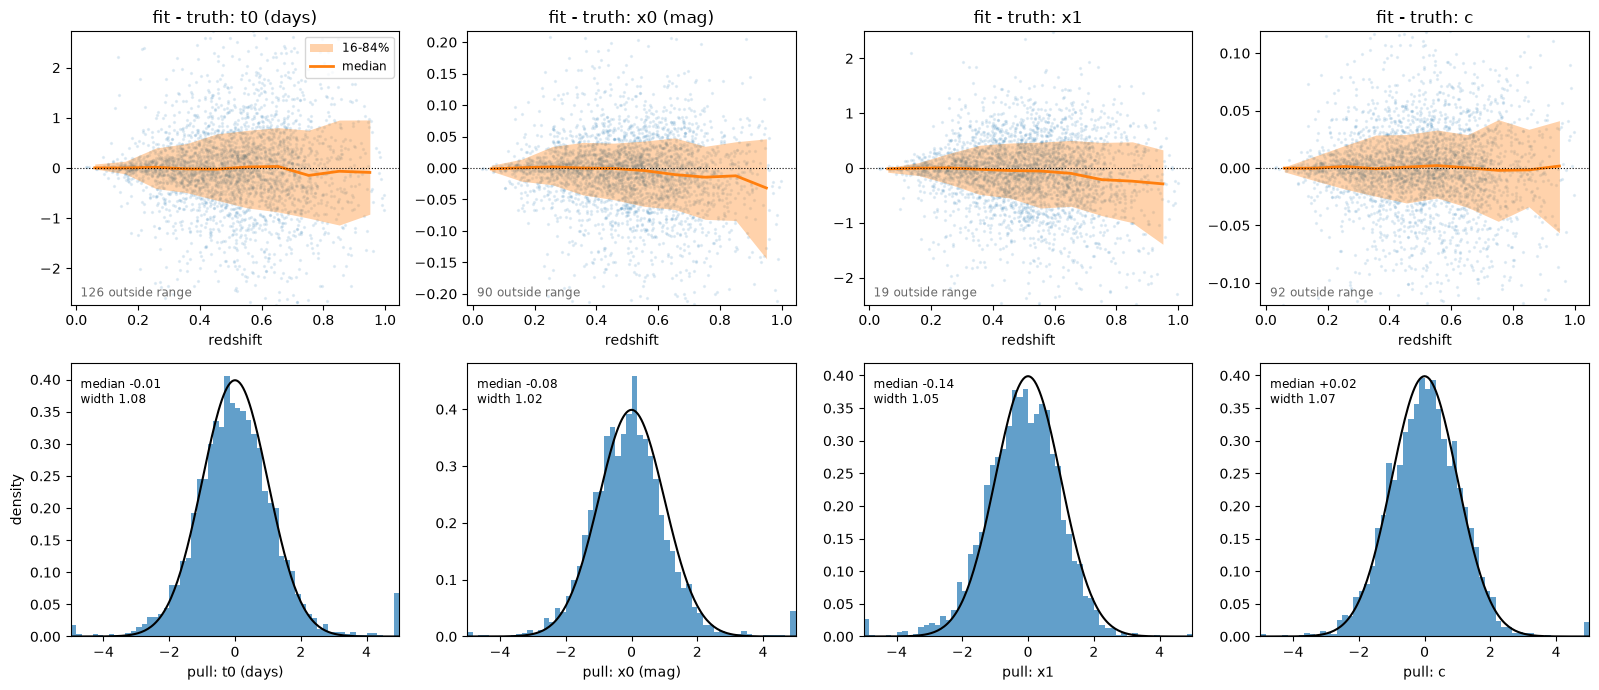

Residuals for the 3,287 objects passing the cuts (median and 16-84% range):
   t0 (days): -0.0048  [-0.6809, +0.6769]
    x0 (mag): -0.0024  [-0.0543, +0.0394]
          x1: -0.0405  [-0.6233, +0.4166]
           c: +0.0003  [-0.0283, +0.0298]


In [15]:
# Compare the fitted parameters to the true values for the objects passing the cuts. The top row shows the
# residuals as a function of redshift, with the median and 16-84th percentile range in redshift bins. The
# y-axes span four times the overall 16-84th percentile range; the number of points outside is noted in each panel.
# The bottom row shows the pulls, (fit - truth) / error, which should follow a unit Gaussian (black curve) if
# the fit uncertainties are correct. Pulls beyond +/-5 are shown in the end bins.
good = fit_results[fit_results["passes_cuts"]]
mag_per_dex = 2.5 / np.log(10.0)
residuals = {
    "t0 (days)": (good["fit_t0"] - good["true_t0"], good["err_t0"]),
    "x0 (mag)": (
        -2.5 * np.log10(good["fit_x0"] / good["true_x0"]),
        mag_per_dex * good["err_x0"] / good["fit_x0"],
    ),
    "x1": (good["fit_x1"] - good["true_x1"], good["err_x1"]),
    "c": (good["fit_c"] - good["true_c"], good["err_c"]),
}
redshift = good["redshift"].to_numpy()
z_edges = np.linspace(Z_MIN, Z_MAX, 11)
z_centers = 0.5 * (z_edges[1:] + z_edges[:-1])
z_bin = np.digitize(redshift, z_edges) - 1
pull_grid = np.linspace(-5, 5, 201)

fig, axes = plt.subplots(2, len(residuals), figsize=(4 * len(residuals), 7))
for col, (label, (resid, err)) in enumerate(residuals.items()):
    resid = resid.to_numpy()
    pull = resid / err.to_numpy()

    # Residuals vs. redshift.
    ax = axes[0, col]
    q16, q84 = np.nanpercentile(resid, [16, 84])
    half_range = 4.0 * max(abs(q16), abs(q84))
    n_outside = np.sum(np.abs(resid) > half_range)
    ax.scatter(redshift, resid, s=2, color="tab:blue", alpha=0.1, rasterized=True)
    pct = np.array(
        [np.nanpercentile(resid[z_bin == b], [16, 50, 84]) for b in range(len(z_centers))]
    )
    ax.fill_between(
        z_centers, pct[:, 0], pct[:, 2], color="tab:orange", alpha=0.35, lw=0, label="16-84%"
    )
    ax.plot(z_centers, pct[:, 1], color="tab:orange", lw=2, label="median")
    ax.axhline(0.0, color="black", lw=0.8, ls=":")
    ax.set_ylim(-half_range, half_range)
    ax.set_xlabel("redshift")
    ax.set_title(f"fit - truth: {label}")
    ax.text(
        0.03,
        0.03,
        f"{n_outside} outside range",
        transform=ax.transAxes,
        fontsize="small",
        color="dimgray",
    )

    # Pull distribution.
    ax = axes[1, col]
    q16, q50, q84 = np.nanpercentile(pull, [16, 50, 84])
    ax.hist(
        np.clip(pull, -5, 5), bins=np.linspace(-5, 5, 61), density=True, color="tab:blue", alpha=0.7
    )
    ax.plot(pull_grid, np.exp(-0.5 * pull_grid**2) / np.sqrt(2.0 * np.pi), color="black", lw=1.5)
    ax.set_xlim(-5, 5)
    ax.set_xlabel(f"pull: {label}")
    ax.text(
        0.03,
        0.95,
        f"median {q50:+.2f}\nwidth {0.5 * (q84 - q16):.2f}",
        transform=ax.transAxes,
        va="top",
        fontsize="small",
    )
axes[0, 0].legend(loc="upper right", fontsize="small")
axes[1, 0].set_ylabel("density")
fig.tight_layout()
plt.show()

print(f"Residuals for the {len(good):,} objects passing the cuts (median and 16-84% range):")
for label, (resid, _) in residuals.items():
    q16, q50, q84 = np.nanpercentile(resid, [16, 50, 84])
    print(f"  {label:>10s}: {q50:+.4f}  [{q16:+.4f}, {q84:+.4f}]")

## Next steps

* **Scale up:** set `N_SIM` to the full population (`n_total`, a few million), or run many independent seeds as separate batch jobs on a cluster and combine the output files.
* **Population:** add intrinsic scatter (see `intrinsic_scatter.ipynb`), hosts (`plasticc_snia.ipynb`), and Milky Way extinction.
* **Model mismatch:** fit with a different model than the one used to simulate (for example, simulate with `salt3-nir` and fit with `salt2-h17`) to test model systematics.
* **Survey:** add the deep drilling fields, or switch to a newer OpSim baseline by changing `OPSIM_FILE`.
* **Cosmologly:** allow for non-standard cosmologies